# HOUSE PRICE PREDICTION USING STATISTICAL MACHINE LEARNING
**CSET-211 – Statistical Machine Learning**

---



Submitted By:

Name: Musky Kumar  
Enrollment No.: S25CSEU2339

Name: Naman dudeja  
Enrollment No.: S25CSEU2331

Name: Aditya verma  
Enrollment No.: S25CSEU2342


Course: CSET-211  
Project Type: Statistical Machine Learning Project

# Introduction

House prices are influenced by various factors such as property area, number of bedrooms and bathrooms, property age, parking availability, location, floor, and accessibility to transportation. Due to the large number of factors involved, estimating the appropriate price of a house manually can be difficult.

This project, “House Price Prediction Using Statistical Machine Learning,” aims to develop a machine learning-based system that can predict the estimated price of a house using its property-related features. The project applies statistical analysis, data visualization, data preprocessing, and machine learning techniques to identify relationships between different features and house prices.

Multiple regression algorithms, including Linear Regression, Decision Tree Regression, and Random Forest Regression, will be implemented and compared. Their performance will be evaluated using metrics such as Mean Absolute Error (MAE), Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and R-squared (R²).

The final objective is to develop an interactive house-price prediction system where users can enter property details and receive an estimated house price.

# Problem Statement

House prices vary significantly depending on property characteristics such as area, number of bedrooms, bathrooms, age, parking, location, and accessibility. It can be challenging to estimate a suitable price by considering all these factors manually. Therefore, there is a need for a data-driven system that can analyze historical housing data and predict house prices. This project aims to develop a statistical machine learning model that uses property features to predict house prices and compares different regression algorithms based on their prediction performance.

# Objectives

Put these underneath:

-To collect and analyze housing data.  
-To perform data cleaning and preprocessing.  
-To analyze relationships between property features and house prices.  
-To visualize important patterns using graphs and statistical analysis.  
-To implement Linear Regression, Decision Tree Regression, and Random Forest Regression.  
-To evaluate the models using MAE, MSE, RMSE, and R².  
-To identify important features affecting house prices.  
-To develop an interactive house-price prediction application.  

In [ ]:
from google.colab import files
uploaded = files.upload()

import pandas as pd
import numpy as np

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Dataset Loaded Successfully!")
print("File:", filename)
print("Dataset Shape:", df.shape)

display(df.head())

Saving kagal-house_prices.csv to kagal-house_prices (1).csv
Dataset Loaded Successfully!
File: kagal-house_prices (1).csv
Dataset Shape: (187531, 21)


,Index,Title,Description,Amount(in rupees),Price (in rupees),location,Carpet Area,Status,Floor,Transaction,...,facing,overlooking,Society,Bathroom,Balcony,Car Parking,Ownership,Super Area,Dimensions,Plot Area
0,0,1 BHK Ready to Occupy Flat for sale in Srushti...,"Bhiwandi, Thane has an attractive 1 BHK Flat f...",42 Lac,6000.0,thane,500 sqft,Ready to Move,10 out of 11,Resale,...,NaN,NaN,Srushti Siddhi Mangal Murti Complex,1,2,NaN,NaN,NaN,NaN,NaN
1,1,2 BHK Ready to Occupy Flat for sale in Dosti V...,One can find this stunning 2 BHK flat for sale...,98 Lac,13799.0,thane,473 sqft,Ready to Move,3 out of 22,Resale,...,East,Garden/Park,Dosti Vihar,2,NaN,1 Open,Freehold,NaN,NaN,NaN
2,2,2 BHK Ready to Occupy Flat for sale in Sunrise...,Up for immediate sale is a 2 BHK apartment in ...,1.40 Cr,17500.0,thane,779 sqft,Ready to Move,10 out of 29,Resale,...,East,Garden/Park,Sunrise by Kalpataru,2,NaN,1 Covered,Freehold,NaN,NaN,NaN
3,3,1 BHK Ready to Occupy Flat for sale Kasheli,This beautiful 1 BHK Flat is available for sal...,25 Lac,NaN,thane,530 sqft,Ready to Move,1 out of 3,Resale,...,NaN,NaN,NaN,1,1,NaN,NaN,NaN,NaN,NaN
4,4,2 BHK Ready to Occupy Flat for sale in TenX Ha...,"This lovely 2 BHK Flat in Pokhran Road, Thane ...",1.60 Cr,18824.0,thane,635 sqft,Ready to Move,20 out of 42,Resale,...,West,"Garden/Park, Main Road",TenX Habitat Raymond Realty,2,NaN,1 Covered,Co-operative Society,NaN,NaN,NaN


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Import required machine learning libraries

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("All machine learning libraries imported successfully!")

All machine learning libraries imported successfully!


In [ ]:
import pandas as pd

df = pd.read_csv('/content/kagal-house_prices.csv')

df = pd.read_csv('kagal-house_prices.csv')

print("First 5 rows:")
display(df.head())

print("Dataset Shape:")
print(df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
display(df.describe())

First 5 rows:


,Index,Title,Description,Amount(in rupees),Price (in rupees),location,Carpet Area,Status,Floor,Transaction,...,facing,overlooking,Society,Bathroom,Balcony,Car Parking,Ownership,Super Area,Dimensions,Plot Area
0,0,1 BHK Ready to Occupy Flat for sale in Srushti...,"Bhiwandi, Thane has an attractive 1 BHK Flat f...",42 Lac,6000.0,thane,500 sqft,Ready to Move,10 out of 11,Resale,...,NaN,NaN,Srushti Siddhi Mangal Murti Complex,1,2,NaN,NaN,NaN,NaN,NaN
1,1,2 BHK Ready to Occupy Flat for sale in Dosti V...,One can find this stunning 2 BHK flat for sale...,98 Lac,13799.0,thane,473 sqft,Ready to Move,3 out of 22,Resale,...,East,Garden/Park,Dosti Vihar,2,NaN,1 Open,Freehold,NaN,NaN,NaN
2,2,2 BHK Ready to Occupy Flat for sale in Sunrise...,Up for immediate sale is a 2 BHK apartment in ...,1.40 Cr,17500.0,thane,779 sqft,Ready to Move,10 out of 29,Resale,...,East,Garden/Park,Sunrise by Kalpataru,2,NaN,1 Covered,Freehold,NaN,NaN,NaN
3,3,1 BHK Ready to Occupy Flat for sale Kasheli,This beautiful 1 BHK Flat is available for sal...,25 Lac,NaN,thane,530 sqft,Ready to Move,1 out of 3,Resale,...,NaN,NaN,NaN,1,1,NaN,NaN,NaN,NaN,NaN
4,4,2 BHK Ready to Occupy Flat for sale in TenX Ha...,"This lovely 2 BHK Flat in Pokhran Road, Thane ...",1.60 Cr,18824.0,thane,635 sqft,Ready to Move,20 out of 42,Resale,...,West,"Garden/Park, Main Road",TenX Habitat Raymond Realty,2,NaN,1 Covered,Co-operative Society,NaN,NaN,NaN


Dataset Shape:
(187531, 21)

Missing Values:
Index                     0
Title                     0
Description            3023
Amount(in rupees)         0
Price (in rupees)     17665
location                  0
Carpet Area           80673
Status                  615
Floor                  7077
Transaction              83
Furnishing             2897
facing                70233
overlooking           81436
Society              109678
Bathroom                828
Balcony               48935
Car Parking          103357
Ownership             65517
Super Area           107685
Dimensions           187531
Plot Area            187531
dtype: int64

Statistical Summary:


,Index,Price (in rupees),Dimensions,Plot Area
count,187531.000000,1.698660e+05,0.0,0.0
mean,93765.000000,7.583772e+03,NaN,NaN
std,54135.681003,2.724171e+04,NaN,NaN
min,0.000000,0.000000e+00,NaN,NaN
25%,46882.500000,4.297000e+03,NaN,NaN
50%,93765.000000,6.034000e+03,NaN,NaN
75%,140647.500000,9.450000e+03,NaN,NaN
max,187530.000000,6.700000e+06,NaN,NaN


In [ ]:
import pandas as pd
import numpy as np
import re

# Function to convert property prices into numerical rupees
def convert_price(value):

    value = str(value).replace(',', '').strip().lower()

    number = re.findall(r'\d+\.?\d*', value)

    if not number:
        return np.nan

    number = float(number[0])

    if 'cr' in value:
        return number * 10000000

    elif 'lac' in value or 'lakh' in value:
        return number * 100000

    else:
        return number

print("Price conversion function created successfully!")

Price conversion function created successfully!


In [ ]:
# Remove unnecessary and text columns for initial model
df = df.dropna(axis=1, how='all')
df = df.drop(columns=['Index', 'Title', 'Description',
                      'Society', 'Dimensions', 'Plot Area',
                      'Amount(in rupees)', 'Status'], errors='ignore')

# Convert Carpet Area into numerical values
df['Carpet Area'] = df['Carpet Area'].astype(str).str.extract(r'([\d.]+)').astype(float)

# Convert Bathroom and Balcony into numerical values
df['Bathroom'] = pd.to_numeric(df['Bathroom'], errors='coerce')
df['Balcony'] = pd.to_numeric(df['Balcony'], errors='coerce')

# Target variable
y = pd.read_csv('kagal-house_prices.csv')['Amount(in rupees)'].apply(convert_price)

# Select numerical features for initial model
X = df[['Carpet Area', 'Bathroom', 'Balcony']].copy()

# Remove rows with missing target
valid = y.notna()
X = X.loc[valid]
y = y.loc[valid]

# Fill missing feature values
X = X.fillna(X.median())

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Train models
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=8, random_state=42),
    "Random Forest": RandomForestRegressor(
        n_estimators=100, max_depth=12, random_state=42, n_jobs=-1
    )
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    prediction = model.predict(X_test)

    mae = mean_absolute_error(y_test, prediction)
    mse = mean_squared_error(y_test, prediction)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, prediction)

    results.append([name, mae, mse, rmse, r2])

results_df = pd.DataFrame(
    results, columns=['Model', 'MAE', 'MSE', 'RMSE', 'R2']
)

display(results_df)

,Model,MAE,MSE,RMSE,R2
0,Linear Regression,6.494273e+06,5.760723e+15,7.589943e+07,0.013461
1,Decision Tree,4.238575e+06,5.742755e+15,7.578097e+07,0.016538
2,Random Forest,3.961231e+06,5.736389e+15,7.573896e+07,0.017629


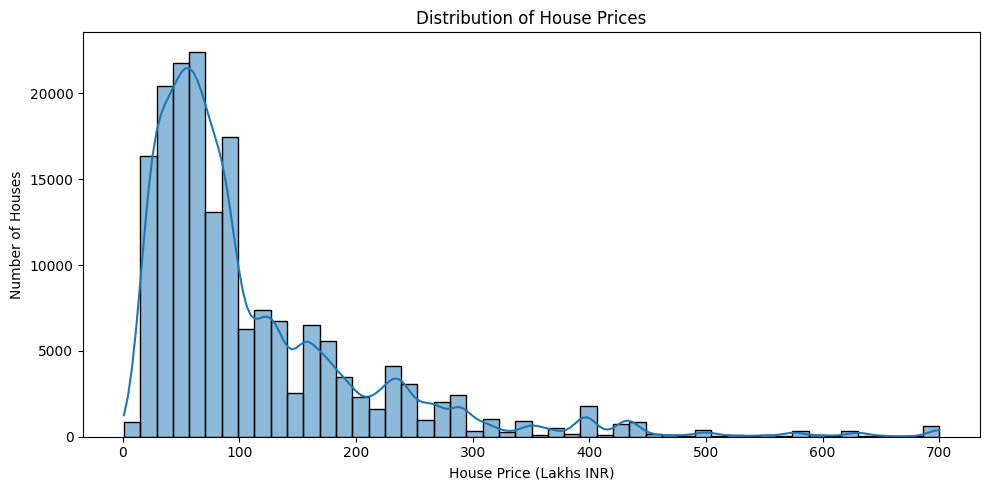

In [ ]:
# Load and convert the price column to avoid KeyError
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

if 'Price_INR' not in df.columns:
    raw_amounts = pd.read_csv('kagal-house_prices.csv')['Amount(in rupees)']
    df['Price_INR'] = raw_amounts.apply(convert_price)

# Remove invalid and extreme values for visualization only
price_data = df['Price_INR'].dropna()

# Display prices up to the 99th percentile
upper_limit = price_data.quantile(0.99)

price_data = price_data[price_data <= upper_limit]

plt.figure(figsize=(10,5))

sns.histplot(
    price_data / 100000,
    bins=50,
    kde=True
)

plt.title("Distribution of House Prices")
plt.xlabel("House Price (Lakhs INR)")
plt.ylabel("Number of Houses")

plt.tight_layout()
plt.show()

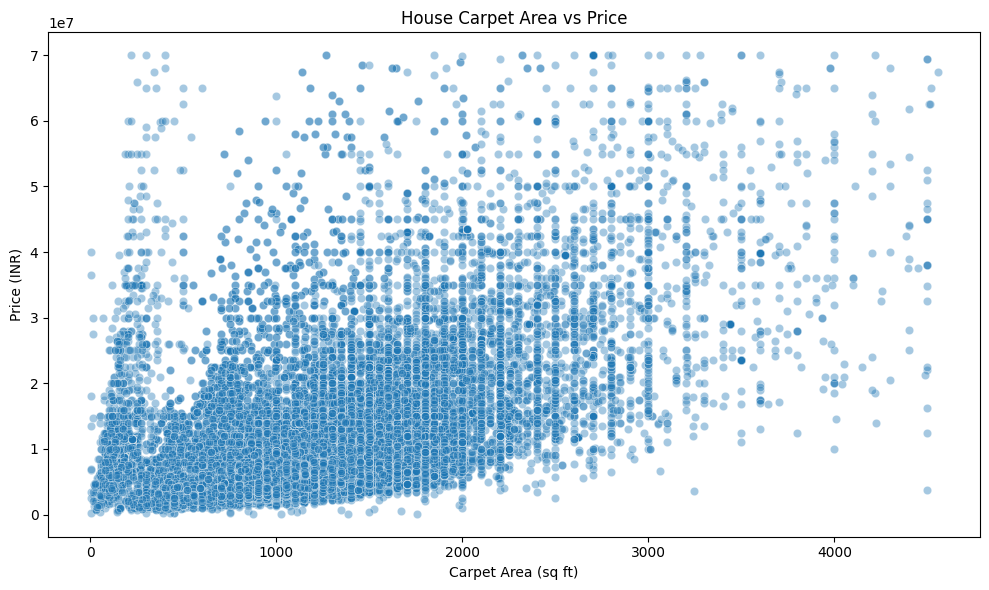

In [ ]:
# Extract numerical carpet area
area = pd.to_numeric(
    df['Carpet Area'].astype(str).str.extract(r'([\d.]+)')[0],
    errors='coerce'
)

# Prepare plotting data
plot_df = pd.DataFrame({
    'Area_sqft': area,
    'Price_INR': df['Price_INR']
}).dropna()

# Remove extreme values for visualization only
plot_df = plot_df[
    (plot_df['Area_sqft'] <= plot_df['Area_sqft'].quantile(0.99)) &
    (plot_df['Price_INR'] <= plot_df['Price_INR'].quantile(0.99))
]

# Scatter plot
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=plot_df,
    x='Area_sqft',
    y='Price_INR',
    alpha=0.4
)

plt.title("House Carpet Area vs Price")
plt.xlabel("Carpet Area (sq ft)")
plt.ylabel("Price (INR)")

plt.tight_layout()
plt.show()

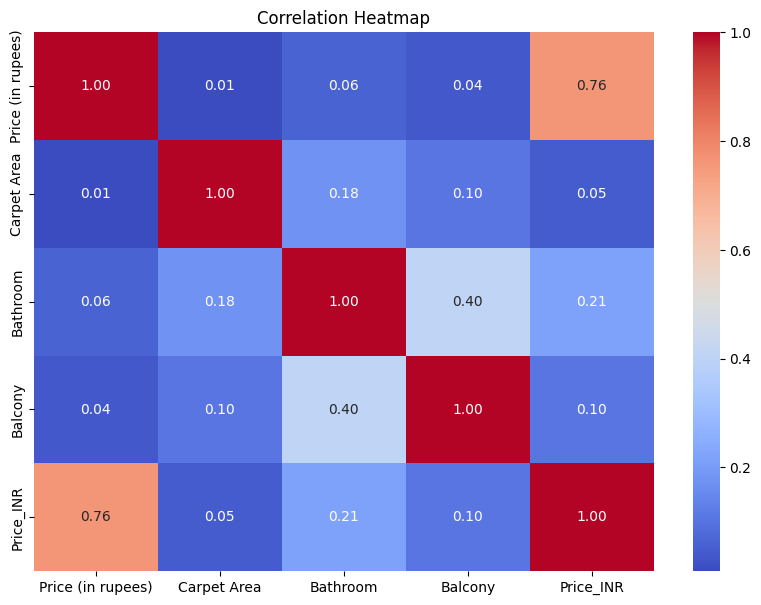

In [ ]:
plt.figure(figsize=(10,7))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")

plt.show()

In [ ]:
# Reload the original Kaggle dataset
df = pd.read_csv('kagal-house_prices.csv')

# Recreate the numerical target column
df['Price_INR'] = df['Amount(in rupees)'].apply(convert_price)

print("Original dataset restored!")
print("Dataset Shape:", df.shape)

Original dataset restored!
Dataset Shape: (187531, 22)


In [ ]:
# Extract BHK (Bedrooms) from property title
df['BHK'] = pd.to_numeric(
    df['Title'].str.extract(r'(\d+)\s*BHK', flags=re.IGNORECASE)[0],
    errors='coerce'
)

# Extract Carpet Area in square feet
df['Carpet_Area_sqft'] = pd.to_numeric(
    df['Carpet Area'].astype(str).str.extract(r'([\d.]+)')[0],
    errors='coerce'
)

# Extract Super Area in square feet
df['Super_Area_sqft'] = pd.to_numeric(
    df['Super Area'].astype(str).str.extract(r'([\d.]+)')[0],
    errors='coerce'
)

# Convert Bathroom and Balcony into numeric values
df['Bathroom_num'] = pd.to_numeric(df['Bathroom'], errors='coerce')
df['Balcony_num'] = pd.to_numeric(df['Balcony'], errors='coerce')

print("Feature Engineering Completed!")

display(df[['BHK', 'Carpet_Area_sqft',
            'Super_Area_sqft', 'Bathroom_num',
            'Balcony_num']].head())

Feature Engineering Completed!


,BHK,Carpet_Area_sqft,Super_Area_sqft,Bathroom_num,Balcony_num
0,1.0,500.0,NaN,1.0,2.0
1,2.0,473.0,NaN,2.0,NaN
2,2.0,779.0,NaN,2.0,NaN
3,1.0,530.0,NaN,1.0,1.0
4,2.0,635.0,NaN,2.0,NaN


In [ ]:
# Check missing values in selected features

features = [
    'BHK',
    'Carpet_Area_sqft',
    'Super_Area_sqft',
    'Bathroom_num',
    'Balcony_num',
    'Price_INR'
]

print("Missing Values Before Cleaning:")
print(df[features].isnull().sum())

# Fill missing numerical values with median
for col in features:
    if col != 'Price_INR':
        df[col] = df[col].fillna(df[col].median())

# Remove rows where target price is missing
df = df.dropna(subset=['Price_INR'])

print("\nMissing Values After Cleaning:")
print(df[features].isnull().sum())

print("\nFinal Dataset Shape:", df.shape)

Missing Values Before Cleaning:
BHK                    921
Carpet_Area_sqft     80673
Super_Area_sqft     107685
Bathroom_num           863
Balcony_num          48957
Price_INR             9684
dtype: int64

Missing Values After Cleaning:
BHK                 0
Carpet_Area_sqft    0
Super_Area_sqft     0
Bathroom_num        0
Balcony_num         0
Price_INR           0
dtype: int64

Final Dataset Shape: (177847, 27)


In [ ]:
# Create separate modelling dataset
model_df = df.copy()

# Select useful numerical and categorical features
selected_features = [
    'BHK',
    'Carpet_Area_sqft',
    'Super_Area_sqft',
    'Bathroom_num',
    'Balcony_num',
    'location',
    'Furnishing',
    'Transaction',
    'facing',
    'Ownership'
]

# Create input and target variables
X = model_df[selected_features]
y = model_df['Price_INR']

print("Input Features:", X.shape)
print("Target Variable:", y.shape)

display(X.head())

Input Features: (177847, 10)
Target Variable: (177847,)


,BHK,Carpet_Area_sqft,Super_Area_sqft,Bathroom_num,Balcony_num,location,Furnishing,Transaction,facing,Ownership
0,1.0,500.0,1250.0,1.0,2.0,thane,Unfurnished,Resale,NaN,NaN
1,2.0,473.0,1250.0,2.0,2.0,thane,Semi-Furnished,Resale,East,Freehold
2,2.0,779.0,1250.0,2.0,2.0,thane,Unfurnished,Resale,East,Freehold
3,1.0,530.0,1250.0,1.0,1.0,thane,Unfurnished,Resale,NaN,NaN
4,2.0,635.0,1250.0,2.0,2.0,thane,Unfurnished,Resale,West,Co-operative Society


In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

# Separate numerical and categorical features

numeric_features = [
    'BHK',
    'Carpet_Area_sqft',
    'Super_Area_sqft',
    'Bathroom_num',
    'Balcony_num'
]

categorical_features = [
    'location',
    'Furnishing',
    'Transaction',
    'facing',
    'Ownership'
]

# Numerical preprocessing
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        min_frequency=50
    ))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

# Split dataset: 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)
print("Preprocessing Setup Completed!")

Training Data: (142277, 10)
Testing Data: (35570, 10)
Preprocessing Setup Completed!


In [ ]:
# Define machine learning models
models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=15,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        random_state=42,
        n_jobs=-1
    )
}

results = []

# Train and evaluate each model
for name, model in models.items():

    print("Training:", name)

    pipeline = Pipeline([
        ('preprocessing', preprocessor),
        ('model', model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)

    results.append([name, mae, mse, rmse, r2])

# Display comparison
results_df = pd.DataFrame(
    results,
    columns=['Model', 'MAE', 'MSE', 'RMSE', 'R2']
)

display(results_df)

Training: Linear Regression
Training: Decision Tree
Training: Random Forest


,Model,MAE,MSE,RMSE,R2
0,Linear Regression,5.796247e+06,5.742773e+15,7.578109e+07,0.016535
1,Decision Tree,2.335351e+06,6.210010e+15,7.880362e+07,-0.063480
2,Random Forest,2.137123e+06,5.936479e+15,7.704855e+07,-0.016637


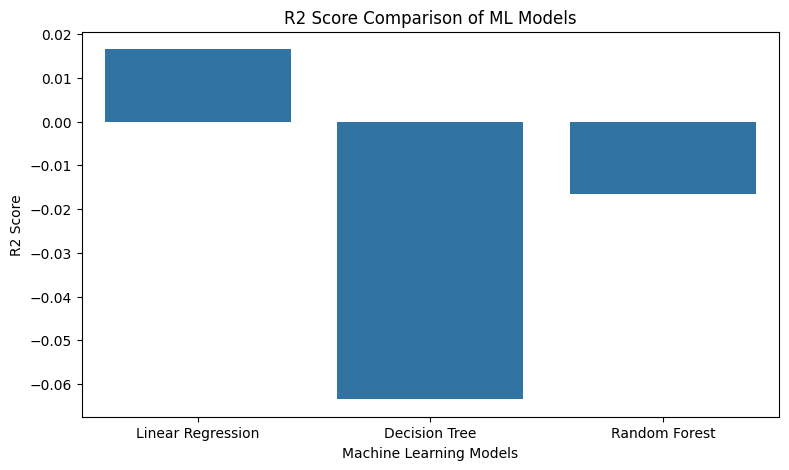

In [ ]:
plt.figure(figsize=(9,5))

sns.barplot(data=results_df, x='Model', y='R2')

plt.title("R2 Score Comparison of ML Models")
plt.ylabel("R2 Score")
plt.xlabel("Machine Learning Models")

plt.show()

In [ ]:
print("Price Statistics:")
display(df['Price_INR'].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
))

Price Statistics:


,Price_INR
count,1.778470e+05
mean,1.198134e+07
std,3.943827e+07
min,1.000000e+05
25%,4.840000e+06
50%,7.800000e+06
75%,1.450000e+07
90%,2.400000e+07
95%,3.390000e+07
99%,7.000000e+07


Records after outlier filtering: 175484

Training: Linear Regression

Training: Decision Tree

Training: Random Forest


,Model,MAE,MSE,RMSE,R2
0,Linear Regression,3.971479e+06,2.430925e+14,1.559143e+07,-1.308654
1,Decision Tree,1.125735e+06,9.378024e+12,3.062356e+06,0.910937
2,Random Forest,1.041484e+06,7.797738e+12,2.792443e+06,0.925945



Best Model: Random Forest


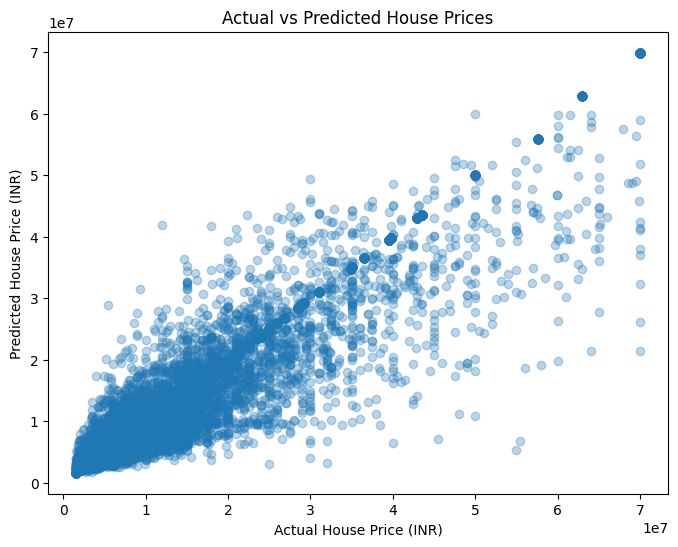


Top 15 Important Features:


,Feature,Importance
3,num__Bathroom_num,0.506240
1,num__Carpet_Area_sqft,0.154296
2,num__Super_Area_sqft,0.101819
50,cat__location_new-delhi,0.049811
27,cat__location_gurgaon,0.023828
45,cat__location_mumbai,0.021940
4,num__Balcony_num,0.019466
39,cat__location_kolkata,0.017153
10,cat__location_bangalore,0.016121
17,cat__location_chennai,0.009683



Best model saved successfully!
Final ML pipeline completed!


In [ ]:
# ==========================================
# FINAL MACHINE LEARNING PIPELINE
# House Price Prediction
# ==========================================

# 1. Prepare data and handle extreme price outliers

final_df = df.copy()

final_df = final_df[
    (final_df['Price_INR'] > 0) &
    (final_df['Price_INR'].notna())
].copy()

lower_limit = final_df['Price_INR'].quantile(0.01)
upper_limit = final_df['Price_INR'].quantile(0.99)

final_df = final_df[
    final_df['Price_INR'].between(lower_limit, upper_limit)
].copy()

print("Records after outlier filtering:", len(final_df))

# 2. Select features and target

selected_features = [
    'BHK',
    'Carpet_Area_sqft',
    'Super_Area_sqft',
    'Bathroom_num',
    'Balcony_num',
    'location',
    'Furnishing',
    'Transaction',
    'facing',
    'Ownership'
]

X_final = final_df[selected_features]
y_final = final_df['Price_INR']

# 3. Split data

X_train_final, X_test_final, y_train_final, y_test_final = train_test_split(
    X_final,
    y_final,
    test_size=0.20,
    random_state=42
)

# 4. Define models

final_models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=18,
        min_samples_leaf=5,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=60,
        max_depth=18,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    )
}

# 5. Train and evaluate models

final_results = []
trained_models = {}

for name, model in final_models.items():

    print("\nTraining:", name)

    pipeline = Pipeline([
        ('preprocessing', preprocessor),
        ('model', model)
    ])

    # Log transformation helps with skewed house prices
    pipeline.fit(X_train_final, np.log1p(y_train_final))

    predictions = np.expm1(pipeline.predict(X_test_final))

    mae = mean_absolute_error(y_test_final, predictions)
    mse = mean_squared_error(y_test_final, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test_final, predictions)

    final_results.append([name, mae, mse, rmse, r2])

    trained_models[name] = pipeline

# 6. Display final comparison

final_results_df = pd.DataFrame(
    final_results,
    columns=['Model', 'MAE', 'MSE', 'RMSE', 'R2']
)

display(final_results_df)

# 7. Select best model using R2

best_model_name = final_results_df.loc[
    final_results_df['R2'].idxmax(), 'Model'
]

best_model = trained_models[best_model_name]

print("\nBest Model:", best_model_name)

# 8. Actual vs Predicted graph

best_predictions = np.expm1(
    best_model.predict(X_test_final)
)

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test_final,
    best_predictions,
    alpha=0.3
)

plt.xlabel("Actual House Price (INR)")
plt.ylabel("Predicted House Price (INR)")
plt.title("Actual vs Predicted House Prices")

plt.show()

# 9. Feature importance (Tree-based models only)

if best_model_name in ["Decision Tree", "Random Forest"]:

    importance = best_model.named_steps['model'].feature_importances_

    feature_names = best_model.named_steps[
        'preprocessing'
    ].get_feature_names_out()

    importance_df = pd.DataFrame({
        'Feature': feature_names,
        'Importance': importance
    }).sort_values(
        by='Importance',
        ascending=False
    )

    print("\nTop 15 Important Features:")
    display(importance_df.head(15))

# 10. Save best model

import joblib

joblib.dump(best_model, 'house_price_best_model.pkl')

print("\nBest model saved successfully!")
print("Final ML pipeline completed!")